# AG News — Task 1: Data EDA

Exploratory analysis and preprocessing walkthrough for the report. All processing lives in `src/ag_news_data.py` (run `python src/ag_news_data.py` to create `data/ag_news/{train,val,test}.csv`); this notebook only reads those files and writes tables/figures to `results/task1_data/`.

- **Dataset:** [fancyzhx/ag_news](https://huggingface.co/datasets/fancyzhx/ag_news) — Zhang, Zhao & LeCun (2015), *Character-level Convolutional Networks for Text Classification*, NeurIPS.
- **Task:** news topic classification into 4 classes: `0 = World`, `1 = Sports`, `2 = Business`, `3 = Sci/Tech`.
- **Splits:** validation is a stratified 10% of the official training split (`SEED = 42`), identical to the split used in the model notebook.

In [1]:
import json
import sys
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Tìm thư mục gốc repo để chạy được dù kernel mở ở root hay ở notebooks/Task X
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "Task 1").is_dir())
sys.path.insert(0, str(ROOT / "data" / "Task 1"))
import ag_news_data as agd

LABEL_NAMES = agd.LABEL_NAMES
CLASS_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
SPLIT_COLORS = ["#2a78d6", "#eb6834", "#1baf7a"]
RESULTS_DIR = ROOT / "data" / "results" / "task1_data"
(RESULTS_DIR / "plots").mkdir(parents=True, exist_ok=True)
(RESULTS_DIR / "tables").mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

# Chưa có data đã xử lý thì chạy pipeline trước
if not (agd.OUTPUT_DIR / "train.csv").exists():
    agd.main()
frames = agd.load_processed()
train_df, val_df, test_df = frames["train"], frames["val"], frames["test"]
train_df.head()

,source_index,label,label_name,text,text_clean,text_nostop,n_tokens
0,6836,1,Sports,10 seconds that change everything ATHENS - Ten...,10 seconds that change everything athens - ten...,10 seconds change athens seconds barely time t...,53
1,90699,1,Sports,Charline Labonte rises to challenge Charline L...,charline labonte rises to challenge charline l...,charline labonte rises challenge charline labo...,31
2,65214,2,Business,Ex-El Paso Traders Plead Guilty to False Repor...,ex-el paso traders plead guilty to false repor...,ex el paso traders plead guilty false reports ...,38
3,87713,1,Sports,Brit deal #39;one year only Even if British a...,brit deal 'one year only even if british and f...,brit deal year british french grands prix held...,42
4,109406,1,Sports,"Signed, Sealed, Delivered CHICAGO - The Cubs a...","signed, sealed, delivered chicago - the cubs a...",signed sealed delivered chicago cubs shortstop...,30


In [2]:
# Kiểm tra cơ bản: văn bản rỗng, trùng lặp, rò rỉ train/test
train_full = pd.concat([train_df, val_df])
print("Empty texts (train/test):", (train_full["text"].str.strip() == "").sum(), (test_df["text"].str.strip() == "").sum())
print("Duplicates in train:", train_full["text"].duplicated().sum())
print("Duplicates in test:", test_df["text"].duplicated().sum())
print("Test texts also in train:", test_df["text"].isin(set(train_full["text"])).sum())

Empty texts (train/test): 0 0
Duplicates in train: 0
Duplicates in test: 0


Test texts also in train: 0


No empty texts, no duplicates and no train/test overlap, so no rows need to be removed.

## 1. Class distribution

AG News ships only a training split (120,000) and a test split (7,600). A stratified 10% of the training split is held out as **validation** for hyperparameter selection; the test split is used only for the final evaluation.

In [3]:
class_dist = pd.DataFrame({name: f["label_name"].value_counts().reindex(LABEL_NAMES) for name, f in frames.items()})
class_dist.loc["Total"] = class_dist.sum()
class_pct = (class_dist.iloc[:-1] / class_dist.iloc[:-1].sum() * 100).round(2)
class_dist.to_csv(RESULTS_DIR / "tables" / "class_distribution.csv")
display(class_dist)
display(class_pct.add_suffix(" (%)"))

,train,val,test
label_name,,,
World,27000,3000,1900
Sports,27000,3000,1900
Business,27000,3000,1900
Sci/Tech,27000,3000,1900
Total,108000,12000,7600


,train (%),val (%),test (%)
label_name,,,
World,25.0,25.0,25.0
Sports,25.0,25.0,25.0
Business,25.0,25.0,25.0
Sci/Tech,25.0,25.0,25.0


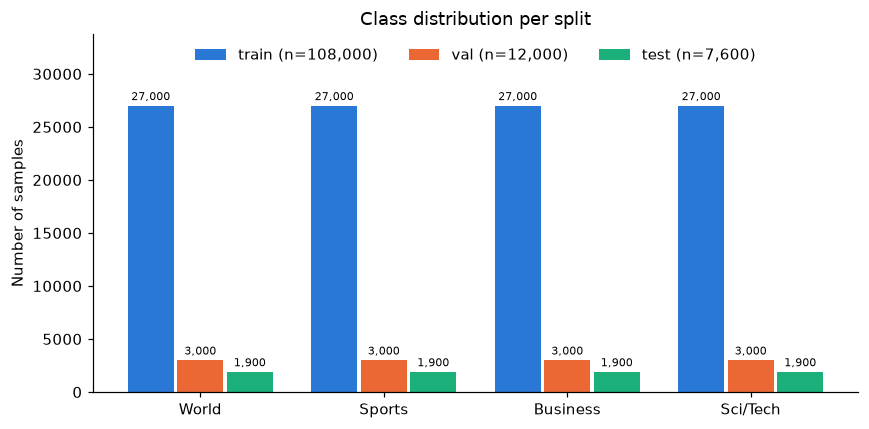

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(LABEL_NAMES))
width = 0.27
for i, (split, color) in enumerate(zip(agd.SPLITS, SPLIT_COLORS)):
    counts = class_dist.loc[LABEL_NAMES, split]
    bars = ax.bar(x + (i - 1) * width, counts, width - 0.02, color=color, label=f"{split} (n={counts.sum():,})")
    ax.bar_label(bars, labels=[f"{v:,}" for v in counts], fontsize=7, padding=2)
ax.set_xticks(x, LABEL_NAMES)
ax.set_ylim(0, class_dist.loc[LABEL_NAMES].values.max() * 1.25)
ax.set_ylabel("Number of samples")
ax.set_title("Class distribution per split")
ax.legend(frameon=False, ncol=3, loc="upper center")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "plots" / "class_distribution.png", bbox_inches="tight")
plt.show()

The dataset is **perfectly balanced** (25% per class in every split), so Accuracy and Macro-F1 are expected to be close. Macro-F1 is still reported because it exposes weak individual classes.

## 2. Raw text inspection

The `text` column already joins the title and the description. Because the articles were scraped from RSS feeds, the text contains noise: HTML entities that lost their `&` (`#39;` = `'`, `#36;` = `$`, `quot;`), escaped HTML tags (`&lt;A HREF=...&gt;`), backslashes used as line breaks, and URLs.

In [5]:
NOISE_PATTERNS = {
    "numeric entity (#39; #36; ...)": r"(?<!&)#\d+;",
    "named entity without & (quot; amp;)": r"(?<![&\w])(?:quot|amp|lt|gt|nbsp);",
    "escaped HTML tag (&lt;...&gt;)": r"&lt;.*?&gt;",
    "backslash line break": r"\\",
    "URL": r"https?://|www\.",
}
all_raw = pd.concat([f["text"] for f in frames.values()])
noise_stats = pd.DataFrame({
    "texts_affected": {k: all_raw.str.contains(p, regex=True).sum() for k, p in NOISE_PATTERNS.items()},
})
noise_stats["percent"] = (noise_stats["texts_affected"] / len(all_raw) * 100).round(2)
noise_stats.to_csv(RESULTS_DIR / "tables" / "raw_noise_stats.csv")
noise_stats

,texts_affected,percent
numeric entity (#39; #36; ...),33348,26.13
named entity without & (quot; amp;),6599,5.17
escaped HTML tag (&lt;...&gt;),5542,4.34
backslash line break,13954,10.94
URL,1946,1.53


About a quarter of all texts contain broken numeric entities (mostly `#39;`, the apostrophe), so cleaning has a visible effect on tokenization (`iraq #39;s` would otherwise become the tokens `iraq`, `39`, `s`).

Text length below is measured in whitespace-separated words of the **raw** text.

In [6]:
for frame in frames.values():
    frame["n_words_raw"] = frame["text"].str.split().str.len()

length_stats = train_df.groupby("label_name")["n_words_raw"].describe(percentiles=[0.5, 0.95]).reindex(LABEL_NAMES)
length_stats.loc["All (train)"] = train_df["n_words_raw"].describe(percentiles=[0.5, 0.95])
length_stats = length_stats.round(1).astype({"count": int, "min": int, "max": int})
length_stats.to_csv(RESULTS_DIR / "tables" / "text_length_stats.csv")
length_stats

,count,mean,std,min,50%,95%,max
label_name,,,,,,,
World,27000,38.9,10.3,11,39.0,55.0,145
Sports,27000,37.8,8.9,8,37.0,52.0,151
Business,27000,37.6,8.2,8,37.0,50.0,134
Sci/Tech,27000,37.2,12.5,8,36.0,56.0,171
All (train),108000,37.9,10.1,8,37.0,53.0,171


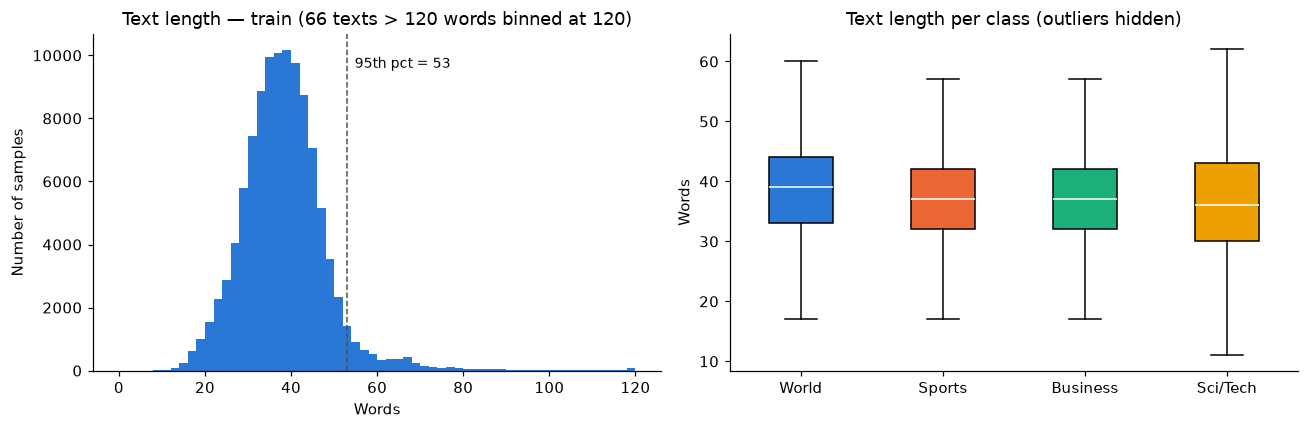

In [7]:
CLIP = 120
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
lengths = train_df["n_words_raw"]
p95 = lengths.quantile(0.95)
axes[0].hist(lengths.clip(upper=CLIP), bins=60, range=(0, CLIP), color=CLASS_COLORS[0])
axes[0].axvline(p95, color="#52514e", linestyle="--", linewidth=1)
axes[0].annotate(f"95th pct = {p95:.0f}", (p95, axes[0].get_ylim()[1] * 0.9), xytext=(5, 0), textcoords="offset points", fontsize=9)
axes[0].set_title(f"Text length — train ({(lengths > CLIP).sum()} texts > {CLIP} words binned at {CLIP})")
axes[0].set_xlabel("Words")
axes[0].set_ylabel("Number of samples")

box = axes[1].boxplot([train_df.loc[train_df["label"] == i, "n_words_raw"] for i in range(4)],
                      tick_labels=LABEL_NAMES, showfliers=False, patch_artist=True)
for patch, color in zip(box["boxes"], CLASS_COLORS):
    patch.set_facecolor(color)
for median in box["medians"]:
    median.set_color("white")
axes[1].set_title("Text length per class (outliers hidden)")
axes[1].set_ylabel("Words")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "plots" / "text_length.png", bbox_inches="tight")
plt.show()

Texts are short (median 37 words) and length is similar across classes, so length alone is not a useful signal. Sci/Tech has the widest spread and the longest outliers.

## 3. Preprocessing (`agd.clean_text`)

1. Restore HTML entities that lost their `&` (`#39;` → `&#39;`, `quot;` → `&quot;`), then `html.unescape` twice because some text is double-escaped.
2. Unicode NFKC normalization; curly quotes, `''` and dashes are mapped to ASCII.
3. Remove HTML tags (exposed after unescaping `&lt;A HREF...&gt;`) and URLs.
4. Replace `\` with a space, re-attach split contractions (`iraq 's` → `iraq's`) and remove spaces left before punctuation.
5. Lowercase and collapse whitespace.

**Punctuation and stopwords are kept** in `text_clean`: scikit-learn vectorizers tokenize on their own, and the LSTM benefits from complete sentences (negations and prepositions carry context). The extra column `text_nostop` (stopwords and punctuation removed with scikit-learn's `ENGLISH_STOP_WORDS`) is provided to compare BoW/TF-IDF with and without stopwords. The tokenizer keeps dotted abbreviations such as `u.s.` as a single token.

News-agency tags such as `(Reuters)` and `(AFP)` are kept: they are part of the input text, not of the label. A few samples still contain advertisement fragments from the RSS feeds (`advertisement ...`); they are rare and are left as is.

In [8]:
print("Empty after cleaning:", {k: int((f["text_clean"] == "").sum()) for k, f in frames.items()})
print("Empty after stopword removal:", {k: int((f["text_nostop"] == "").sum()) for k, f in frames.items()})

# Rác còn sót sau khi làm sạch (chỉ còn vài lỗi gõ có sẵn trong dữ liệu gốc như "&nsbp;")
all_clean = pd.concat([f["text_clean"] for f in frames.values()])
residual = {
    "numeric entity": r"#\d+;",
    "named entity": r"&[a-z]+;|\b(?:quot|amp|nbsp);",
    "HTML tag": r"<[^>]*>",
    "backslash": r"\\",
    "URL": r"https?://\S|www\.\S",
}
pd.Series({k: all_clean.str.contains(p, regex=True).sum() for k, p in residual.items()}, name="texts_affected")

Empty after cleaning: {'train': 0, 'val': 0, 'test': 0}
Empty after stopword removal: {'train': 0, 'val': 0, 'test': 0}


numeric entity    0
named entity      2
HTML tag          0
backslash         0
URL               0
Name: texts_affected, dtype: int64

In [9]:
# Mỗi loại rác lấy một ví dụ trước / sau tiền xử lý
sample_ids = [train_df[train_df["text"].str.contains(p, regex=True)].index[0] for p in NOISE_PATTERNS.values()]
examples = train_df.loc[sample_ids, ["label_name", "text", "text_clean", "text_nostop"]]
examples.to_csv(RESULTS_DIR / "tables" / "preprocessing_examples.csv", index=False)

with pd.option_context("display.max_colwidth", None):
    display(examples)

,label_name,text,text_clean,text_nostop
1,Sports,"Charline Labonte rises to challenge Charline Labonte has served notice she wants to become the next starting goaltender of the Canadian women #39;s hockey team. The 22-year-old from Boisbriand, Que.","charline labonte rises to challenge charline labonte has served notice she wants to become the next starting goaltender of the canadian women's hockey team. the 22-year-old from boisbriand, que.",charline labonte rises challenge charline labonte served notice wants starting goaltender canadian women's hockey team 22 year old boisbriand que
6,Sci/Tech,XBox Owner Sues Microsoft drusoicy writes quot;Reuters is reporting that Sean Burke has filed suit against Microsoft because his XBox system stopped reading discs (games or otherwise) after less than one year of use.,"xbox owner sues microsoft drusoicy writes ""reuters is reporting that sean burke has filed suit against microsoft because his xbox system stopped reading discs (games or otherwise) after less than one year of use.",xbox owner sues microsoft drusoicy writes reuters reporting sean burke filed suit microsoft xbox stopped reading discs games year use
68,World,"Abbas makes election move, possibly to push back activist &lt;b&gt;...&lt;/b&gt; The interim Palestinian leader promised to set a date for internal elections in the ruling Fatah movement, a Cabinet minister said Friday, in an apparent attempt to persuade the head of Fatah #39;s restless young guard to drop out","abbas makes election move, possibly to push back activist... the interim palestinian leader promised to set a date for internal elections in the ruling fatah movement, a cabinet minister said friday, in an apparent attempt to persuade the head of fatah's restless young guard to drop out",abbas makes election possibly push activist interim palestinian leader promised set date internal elections ruling fatah movement cabinet minister said friday apparent attempt persuade head fatah's restless young guard drop
4,Sports,"Signed, Sealed, Delivered CHICAGO - The Cubs and shortstop Nomar Garciaparra have agreed to terms on a one-year deal worth \$8 million. No option years were added to the contract.","signed, sealed, delivered chicago - the cubs and shortstop nomar garciaparra have agreed to terms on a one-year deal worth $8 million. no option years were added to the contract.",signed sealed delivered chicago cubs shortstop nomar garciaparra agreed terms year deal worth 8 million option years added contract
157,Business,"Stocks to Watch Friday U.S. oil major ConocoPhillips is seeking to buy up to 25 percent in Russian oil giant LUKOIL &lt;A HREF=""http://www.investor.reuters.com/FullQuote.aspx?ticker=LKOH.RTS target=/stocks/quickinfo/fullquote""&gt;LKOH.RTS&lt;/A&gt;, booking billions of barrels of new reserves, an industry source familiar with the matter said on Friday. ConocoPhillips shares closed at \$72.70 on the New York Stock Exchange.","stocks to watch friday u.s. oil major conocophillips is seeking to buy up to 25 percent in russian oil giant lukoil lkoh.rts, booking billions of barrels of new reserves, an industry source familiar with the matter said on friday. conocophillips shares closed at $72.70 on the new york stock exchange.",stocks watch friday u.s. oil major conocophillips seeking buy 25 percent russian oil giant lukoil lkoh rts booking billions barrels new reserves industry source familiar matter said friday conocophillips shares closed 72 70 new york stock exchange


## 4. Statistics for the models

- **Vocabulary** built on the training split (tokens with frequency ≥ 2) plus `<PAD>` and `<UNK>`, and the OOV rate of validation/test against it.
- **`max_len`** for the LSTM = 95th percentile of token counts in the training split (tokens from `agd.tokenize`, i.e. words without punctuation).
- The most frequent words per class (stopwords removed) as a sanity check of the labels.

In [10]:
summary = json.loads((agd.OUTPUT_DIR / "data_summary.json").read_text())
pd.Series({k: v for k, v in summary.items() if not isinstance(v, (list, dict))}, name="value").to_frame()

,value
dataset,fancyzhx/ag_news
seed,42
validation_size,0.1
unique_tokens_train,66752
vocab_size_min_freq_2_with_pad_unk,44441
oov_rate_val,0.0106
oov_rate_test,0.0107
tokens_per_text_mean,37.95
tokens_per_text_max,171
max_len_p95,53


In [11]:
top_words = {}
for label in LABEL_NAMES:
    counts = Counter(tok for text in train_df.loc[train_df["label_name"] == label, "text_nostop"] for tok in text.split())
    top_words[label] = [f"{w} ({c:,})" for w, c in counts.most_common(15)]
top_words_df = pd.DataFrame(top_words)
top_words_df.index += 1
top_words_df.to_csv(RESULTS_DIR / "tables" / "top_words_per_class.csv")
top_words_df

,World,Sports,Business,Sci/Tech
1,"said (7,011)","ap (5,616)","said (6,589)","new (6,465)"
2,"ap (5,256)","game (3,857)","reuters (6,224)","microsoft (4,038)"
3,"reuters (4,835)","new (3,752)","new (6,055)","said (3,365)"
4,"iraq (4,644)","win (3,158)","oil (5,699)","ap (3,361)"
5,"president (3,788)","season (3,153)","prices (3,787)","software (3,284)"
6,"new (3,152)","1 (2,997)","company (3,315)","internet (2,996)"
7,"afp (3,061)","team (2,919)","percent (3,129)","reuters (2,943)"
8,"minister (2,982)","world (2,598)","york (3,057)","space (2,379)"
9,"killed (2,840)","night (2,564)","u.s. (2,885)","company (2,166)"
10,"people (2,532)","cup (2,474)","year (2,867)","search (2,063)"


The vocabulary of each class is fairly distinct (World: *iraq, president, minister, killed*; Sports: *game, win, season, team* plus many score digits; Business: *oil, prices, company, percent*; Sci/Tech: *microsoft, software, internet, space*). Agency names (*reuters, ap, afp*) and *said, new* appear in every class and carry little information. Business and Sci/Tech share *company* and technology-company names, so this is the pair expected to be confused most often — to be checked against the confusion matrices in the model notebook.